# Polyimide on silicon — THz extraction, two measurements

Standard transfer-matrix extraction. Each measurement is fitted **on its own**, with its own reference
scan, all six parameters free. No corrections applied, nothing assumed about the two being equivalent.

The stack is built in the order the beam meets the layers, taken from the file name:

| measurement | reference scan | sample scan | stack in the model | date |
|---|---|---|---|---|
| **PI-first** | `PI_silicon_ref_15min.txt` | `PI_silicon_15min.txt` | air → **polyimide** → **silicon** → air | 2026-11-12 |
| **Si-first** | `silicon_PI_ref_15min.txt` | `silicon_PI_15min.txt` | air → **silicon** → **polyimide** → air | 2026-11-16 |

Parameters: `n_PI, k_PI, d_PI` for the polyimide and `n_Si, k_Si, d_Si` for the silicon, with the complex
index written `n − i k`.

## 1. Setup

In [1]:
import os, time
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

torch.set_default_dtype(torch.float64)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.grid': True, 'grid.alpha': 0.3})

C0 = 2.99792458e8
DATA = next((d for d in ('data', '.', 'Data', '../data')
             if os.path.exists(os.path.join(d, 'PI_silicon_15min.txt'))), 'data')

# reference scan, sample scan, and the layer order the beam meets
MEAS = {
    'PI-first': dict(ref='PI_silicon_ref_15min.txt', sam='PI_silicon_15min.txt', order=('PI', 'Si')),
    'Si-first': dict(ref='silicon_PI_ref_15min.txt', sam='silicon_PI_15min.txt', order=('Si', 'PI')),
}
COL = {'PI-first': 'C0', 'Si-first': 'C3'}

# parameter vector is always [n_PI, k_PI, d_PI, n_Si, k_Si, d_Si] - the ORDER argument decides
# which one goes first in the stack, so the same numbers mean the same physical layer on both days.
PNAME = ['n_PI', 'k_PI', 'd_PI', 'n_Si', 'k_Si', 'd_Si']
P0 = np.array([1.75, 0.005, 26.0e-6, 3.35, 0.002, 390e-6])
LO = np.array([1.10, 0.000,  2.0e-6, 2.80, 0.000, 250e-6])
HI = np.array([3.00, 0.300, 80.0e-6, 4.20, 0.060, 500e-6])
SC = np.array([0.10, 0.005,  2.0e-6, 0.05, 0.001,   5e-6])
BAND = (0.25e12, 2.2e12)

### 1.1 Transfer-matrix model

Same conventions as `Simulate.py`. The reference waveform is propagated through the stack, so the
simulated trace is directly comparable with the measured sample trace.

In [2]:
def _layer(n0, nj, Dj, cos, sin, exp):
    c, s = cos(nj*Dj), sin(nj*Dj)
    den = c + 0.5j*(nj/n0 + n0/nj)*s
    r = 0.5j*s*(n0/nj - nj/n0)/den
    t = 1.0/den
    return r, t*exp(1j*n0*Dj), t*t - r*r


def transfer_function(kvec, layers, backend='torch'):
    """T(k) for a stack in air.  layers = [(complex n, thickness), ...] IN BEAM ORDER."""
    if backend == 'torch':
        cos, sin, exp = torch.cos, torch.sin, torch.exp
        n0 = torch.tensor(1.0+0j, dtype=torch.complex128)
        U = torch.zeros_like(kvec, dtype=torch.complex128)
        V = torch.ones_like(kvec, dtype=torch.complex128)
        T = torch.ones_like(kvec, dtype=torch.complex128)
        cast = lambda z: (z if torch.is_tensor(z) else torch.tensor(z)).to(torch.complex128)
    else:
        cos, sin, exp = np.cos, np.sin, np.exp
        n0 = 1.0+0j
        U = np.zeros_like(kvec, dtype=complex); V = np.ones_like(kvec, dtype=complex)
        T = np.ones_like(kvec, dtype=complex); cast = lambda z: np.asarray(z, dtype=complex)
    for nj, dj in layers:
        r, t, s = _layer(n0, cast(nj), cast(kvec)*cast(dj), cos, sin, exp)
        Vlast = V
        U, V = r*V + s*U, V - r*U
        T = T*t*Vlast/V
    return T


def stack(p, order):
    """Build the layer list in beam order from the parameter vector."""
    lay = {'PI': (p[0] - 1j*p[1], p[2]), 'Si': (p[3] - 1j*p[4], p[5])}
    return [lay[k] for k in order]


def simulate(x, p, order, dt, pad=8):
    """Propagate the measured reference x through the stack. Returns the simulated sample trace."""
    xt = torch.as_tensor(np.asarray(x)); L = xt.numel(); N = pad*L
    z = torch.zeros(N); z[:L] = xt
    kvec = 2*np.pi*torch.fft.rfftfreq(N, d=dt)/C0
    pt = p if torch.is_tensor(p) else torch.as_tensor(np.asarray(p, float))
    T = transfer_function(kvec, stack(pt, order))
    return torch.fft.irfft(T*torch.fft.rfft(z), n=N)[:L]


def simulate_np(x, p, order, dt):
    with torch.no_grad():
        return simulate(x, p, order, dt).numpy()


def modelT(f, p, order):
    return transfer_function(2*np.pi*f/C0, stack(np.asarray(p, float), order), backend='numpy')

In [3]:
def read_menlo(path):
    d = np.loadtxt(path, comments='#')
    return d[:, 0] - d[0, 0], d[:, 1]

D = {}
for name, m in MEAS.items():
    t, x = read_menlo(os.path.join(DATA, m['ref']))
    _, y = read_menlo(os.path.join(DATA, m['sam']))
    dt = (t[1]-t[0])*1e-12
    f = np.fft.rfftfreq(len(t), dt)
    T = np.fft.rfft(y)/np.fft.rfft(x)
    band = (f > BAND[0]) & (f < BAND[1])
    D[name] = dict(t=t, x=x, y=y, dt=dt, f=f, T=T, band=band,
                   order=m['order'], sigma=np.std(y[t < 8.0]))
    print(f"{name:9s} stack = air -> {' -> '.join(m['order'])} -> air | "
          f"N={len(t)}  dt={dt*1e15:.2f} fs  window={t[-1]:.1f} ps  noise={D[name]['sigma']:.2e}")

PI-first  stack = air -> PI -> Si -> air | N=1971  dt=32.99 fs  window=65.0 ps  noise=1.47e-03
Si-first  stack = air -> Si -> PI -> air | N=1971  dt=32.99 fs  window=65.0 ps  noise=1.46e-03


## 2. Time domain

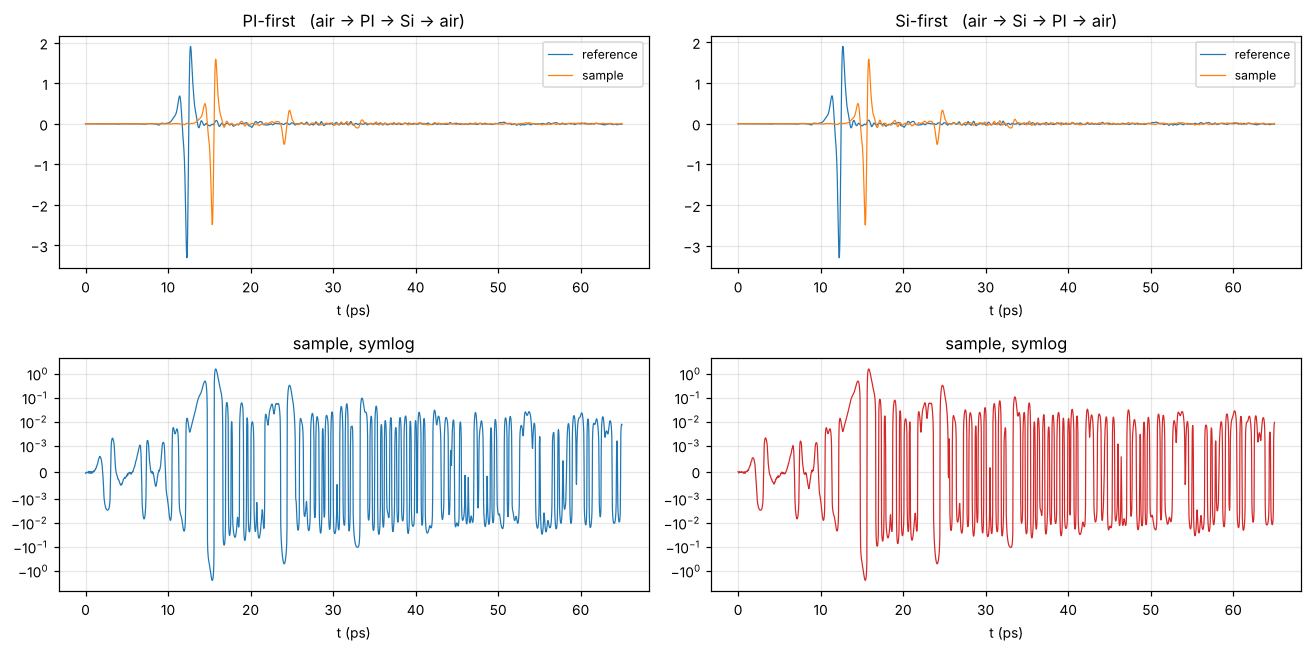

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(12, 6))
for j, (name, d) in enumerate(D.items()):
    ax[0, j].plot(d['t'], d['x'], lw=0.8, label='reference')
    ax[0, j].plot(d['t'], d['y'], lw=0.8, label='sample')
    ax[0, j].set_title(f"{name}   (air -> {' -> '.join(d['order'])} -> air)")
    ax[0, j].legend(fontsize=8); ax[0, j].set_xlabel('t (ps)')
    ax[1, j].plot(d['t'], d['y'], lw=0.8, color=COL[name])
    ax[1, j].set_yscale('symlog', linthresh=1e-3); ax[1, j].set_xlabel('t (ps)')
    ax[1, j].set_title('sample, symlog')
plt.tight_layout(); plt.show()

### 2.1 Pulse and echo timings

In [5]:
def delay_between(a, b, dt, band=(0.2e12, 2.0e12)):
    """Delay of b relative to a, from the slope of the cross-spectral phase (sub-sample)."""
    f = np.fft.rfftfreq(len(a), dt); m = (f > band[0]) & (f < band[1])
    ph = np.unwrap(np.angle(np.fft.rfft(b)[m]/np.fft.rfft(a)[m]))
    c = np.polyfit(f[m], ph, 1)
    return -c[0]/(2*np.pi)

def gate(t, y, tc, half):
    w = np.zeros_like(y); m = np.abs(t - tc) <= half; w[m] = np.hanning(m.sum()); return y*w

for name, d in D.items():
    t, x, y, dt = d['t'], d['x'], d['y'], d['dt']
    ip = np.argmax(np.abs(y))
    dmain = delay_between(x, y, dt)
    decho = delay_between(gate(t, y, t[ip]+0.25, 2.25), gate(t, y, t[ip]+9.0, 2.5),
                          dt, band=(0.2e12, 1.5e12))
    amps = [y[ip]]
    for k in (1, 2, 3):
        m = np.abs(t - (t[ip] + 8.76*k)) < 2.0
        amps.append(y[m][np.argmax(np.abs(y[m]))])
    a = np.array(amps)
    d['dmain'], d['decho'] = dmain, decho
    print(f'{name}:')
    print(f'   sample delayed vs its reference : {dmain*1e12:.4f} ps  '
          f'(= {dmain*C0*1e6:.1f} um of optical path)')
    print(f'   internal echo round trip        : {decho*1e12:.4f} ps  '
          f'-> n_Si*d_Si = {decho*C0/2*1e6:.1f} um')
    print(f'   echo amplitudes                 : {np.round(a,4)}   ratios {np.round(np.abs(a[1:]/a[:-1]),4)}')

PI-first:
   sample delayed vs its reference : 3.0857 ps  (= 925.1 um of optical path)
   internal echo round trip        : 8.7644 ps  -> n_Si*d_Si = 1313.8 um
   echo amplitudes                 : [-2.4874 -0.5075 -0.1035  0.0307]   ratios [0.204  0.2038 0.2964]
Si-first:
   sample delayed vs its reference : 3.1667 ps  (= 949.4 um of optical path)
   internal echo round trip        : 8.7639 ps  -> n_Si*d_Si = 1313.7 um
   echo amplitudes                 : [-2.4822 -0.5079  0.1078  0.0335]   ratios [0.2046 0.2123 0.3108]


The echo spacing of ~8.8 ps is the silicon slab. The polyimide's own round trip would be ~0.3 ps, buried
under the main pulse, so the film never appears as a separate echo — it acts inside the main pulse and on
the echo amplitudes.

## 3. Spectra and transfer function

PI-first: peak dynamic range 13719:1, useful to 4.67 THz
Si-first: peak dynamic range 14559:1, useful to 4.71 THz


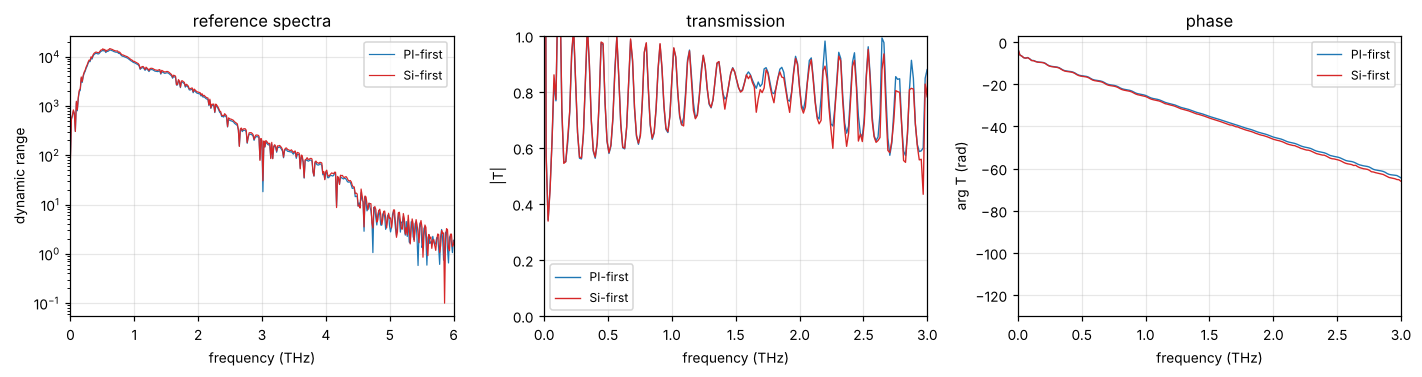

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for name, d in D.items():
    f, X = d['f'], np.fft.rfft(d['x'])
    nf = np.abs(X)[f > 8e12].mean()
    ax[0].semilogy(f/1e12, np.abs(X)/nf, lw=0.8, color=COL[name], label=name)
    ax[1].plot(f/1e12, np.abs(d['T']), lw=0.9, color=COL[name], label=name)
    ax[2].plot(f/1e12, np.unwrap(np.angle(d['T'])), lw=0.9, color=COL[name], label=name)
    print(f'{name}: peak dynamic range {(np.abs(X)/nf).max():.0f}:1, '
          f'useful to {f[(np.abs(X)/nf > 10) & (f > 1e11)].max()/1e12:.2f} THz')
ax[0].set_xlim(0, 6); ax[0].set_ylabel('dynamic range'); ax[0].set_title('reference spectra')
ax[1].set_xlim(0, 3); ax[1].set_ylim(0, 1); ax[1].set_ylabel('|T|'); ax[1].set_title('transmission')
ax[2].set_xlim(0, 3); ax[2].set_ylabel('arg T (rad)'); ax[2].set_title('phase')
for a in ax: a.set_xlabel('frequency (THz)'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Fit

Each measurement is fitted separately against its own reference, in its own layer order, with all six
parameters free. Adam first (as in the quartz/Si notebook), then a least-squares polish from several
starting points — the thin-film-next-to-thick-slab geometry has secondary minima where the polyimide
collapses to ~16 µm, and a single start can land in one.

===== PI-first =====


   it     0  n_PI=1.7465 d_PI= 25.95um  n_Si=3.3433 d_Si= 389.22um  loss=1.2494e-02


   it   500  n_PI=1.7335 d_PI= 25.50um  n_Si=3.2590 d_Si= 400.24um  loss=1.8681e-03


   it  1000  n_PI=1.7358 d_PI= 25.48um  n_Si=3.2577 d_Si= 400.38um  loss=1.8538e-03


   it  1500  n_PI=1.7347 d_PI= 25.46um  n_Si=3.2568 d_Si= 400.48um  loss=1.8475e-03


   it  2000  n_PI=1.7332 d_PI= 25.56um  n_Si=3.2583 d_Si= 400.28um  loss=1.9515e-03


... (2 outputs left out)

   it  1000  n_PI=1.7612 d_PI= 26.79um  n_Si=3.4595 d_Si= 376.85um  loss=2.8792e-03


   it  1500  n_PI=1.7611 d_PI= 26.79um  n_Si=3.4595 d_Si= 376.85um  loss=2.8671e-03


   it  2000  n_PI=1.7618 d_PI= 26.78um  n_Si=3.4593 d_Si= 376.91um  loss=2.8816e-03


   it  2499  n_PI=1.7616 d_PI= 26.78um  n_Si=3.4587 d_Si= 376.86um  loss=2.8933e-03
   (18 s)


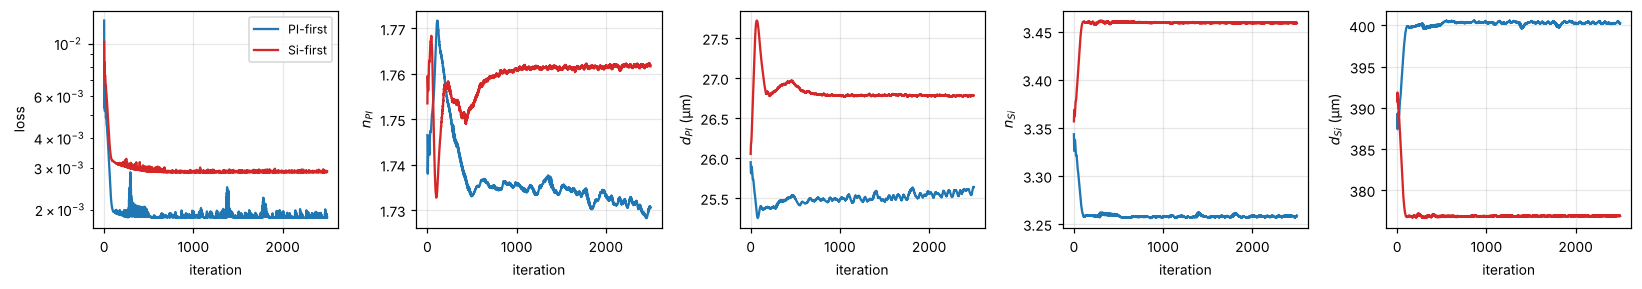

In [7]:
def adam_fit(name, n_iters=2500, lr=2e-3, print_step=500):
    d = D[name]; x, y, dt, order = d['x'], d['y'], d['dt'], d['order']
    yt = torch.as_tensor(y)
    u = torch.ones(6, requires_grad=True)
    opt = torch.optim.Adam([u], lr=lr); hist = []; t0 = time.time()
    for i in range(n_iters):
        opt.zero_grad()
        p = u*torch.as_tensor(P0)
        resid = yt - simulate(x, p, order, dt)
        loss = resid.abs().mean() + torch.mean(torch.log(torch.cosh(resid + 1e-12)))
        loss.backward(); opt.step()
        hist.append(np.concatenate([u.detach().numpy()*P0, [loss.item()]]))
        if i % print_step == 0 or i == n_iters-1:
            q = u.detach().numpy()*P0
            print(f'   it {i:5d}  n_PI={q[0]:.4f} d_PI={q[2]*1e6:6.2f}um  '
                  f'n_Si={q[3]:.4f} d_Si={q[5]*1e6:7.2f}um  loss={loss.item():.4e}')
    print(f'   ({time.time()-t0:.0f} s)')
    return np.array(hist).T

traj = {}
for name in MEAS:
    print(f'===== {name} =====')
    traj[name] = adam_fit(name)

fig, ax = plt.subplots(1, 5, figsize=(15, 2.7))
for name, tr in traj.items():
    ax[0].semilogy(tr[6], color=COL[name], label=name)
    for k, i in enumerate([0, 2, 3, 5]):
        ax[k+1].plot(tr[i]*(1e6 if i in (2, 5) else 1), color=COL[name])
ax[0].set_ylabel('loss'); ax[0].legend(fontsize=8)
for a, lab in zip(ax[1:], ['$n_{PI}$', '$d_{PI}$ (µm)', '$n_{Si}$', '$d_{Si}$ (µm)']): a.set_ylabel(lab)
for a in ax: a.set_xlabel('iteration')
plt.tight_layout(); plt.show()

In [8]:
STARTS = [P0,
          np.array([1.80, 0.005, 24.0e-6, 3.42, 0.002, 382e-6]),
          np.array([1.70, 0.005, 28.0e-6, 3.30, 0.002, 396e-6])]

def lsq_fit(name, starts=None):
    d = D[name]; x, y, dt, order = d['x'], d['y'], d['dt'], d['order']
    def resid(q):
        return (y - simulate_np(x, q, order, dt))/d['sigma']
    best, beste = None, np.inf
    for p0 in (starts or STARTS):
        p0 = np.clip(np.asarray(p0, float), LO + 1e-12, HI - 1e-12)   # Adam is unconstrained
        s = least_squares(resid, p0, bounds=(LO, HI), x_scale=SC, loss='soft_l1', f_scale=3.0)
        e = np.sqrt(np.mean(s.fun**2))
        if e < beste: best, beste = s.x.copy(), e
    return best, beste

FIT = {}
for name in MEAS:
    p, e = lsq_fit(name, starts=[traj[name][:6, -1]] + STARTS)
    FIT[name] = dict(p=p, err=e)
    print(f'{name}: residual {e:.3f} x noise')

PI-first: residual 2.553 x noise


Si-first: residual 3.644 x noise


## 5. Results

In [9]:
print(f'{"":12s}' + ''.join(f'{n:>16s}' for n in MEAS))
print('-'*44)
for i, lab in enumerate(PNAME):
    sc = 1e6 if lab.startswith('d_') else 1
    unit = ' um' if lab.startswith('d_') else ''
    print(f'{lab:12s}' + ''.join(f'{FIT[n]["p"][i]*sc:13.4f}{unit}' for n in MEAS))
print('-'*44)
for lab, fn in [('n_PI * d_PI', lambda p: p[0]*p[2]*1e6), ('n_Si * d_Si', lambda p: p[3]*p[5]*1e6)]:
    print(f'{lab:12s}' + ''.join(f'{fn(FIT[n]["p"]):13.2f} um' for n in MEAS))
print(f'{"residual":12s}' + ''.join(f'{FIT[n]["err"]:16.3f}' for n in MEAS))

print('\n--- refractive index of the polyimide ---')
for n in MEAS:
    p = FIT[n]['p']
    print(f'   {n}: n_PI = {p[0]:.3f}   (d_PI = {p[2]*1e6:.2f} um, n*d = {p[0]*p[2]*1e6:.2f} um)')
v = np.array([FIT[n]['p'][0] for n in MEAS])
w = np.array([FIT[n]['p'][2] for n in MEAS])*1e6
print(f'\n   n_PI  : {v.mean():.3f}  (the two measurements differ by {abs(np.diff(v))[0]:.3f})')
print(f'   d_PI  : {w.mean():.2f} um  (differ by {abs(np.diff(w))[0]:.2f} um)')

                    PI-first        Si-first
--------------------------------------------
n_PI               1.7304       1.7563
k_PI               0.0000       0.0000
d_PI              25.5370 um      26.8265 um
n_Si               3.2569       3.4610
k_Si               0.0009       0.0000
d_Si             400.5018 um     376.6353 um
--------------------------------------------
n_PI * d_PI         44.19 um        47.12 um
n_Si * d_Si       1304.37 um      1303.55 um
residual               2.553           3.644

--- refractive index of the polyimide ---
   PI-first: n_PI = 1.730   (d_PI = 25.54 um, n*d = 44.19 um)
   Si-first: n_PI = 1.756   (d_PI = 26.83 um, n*d = 47.12 um)

   n_PI  : 1.743  (the two measurements differ by 0.026)
   d_PI  : 26.18 um  (differ by 1.29 um)


### 5.1 Fit quality

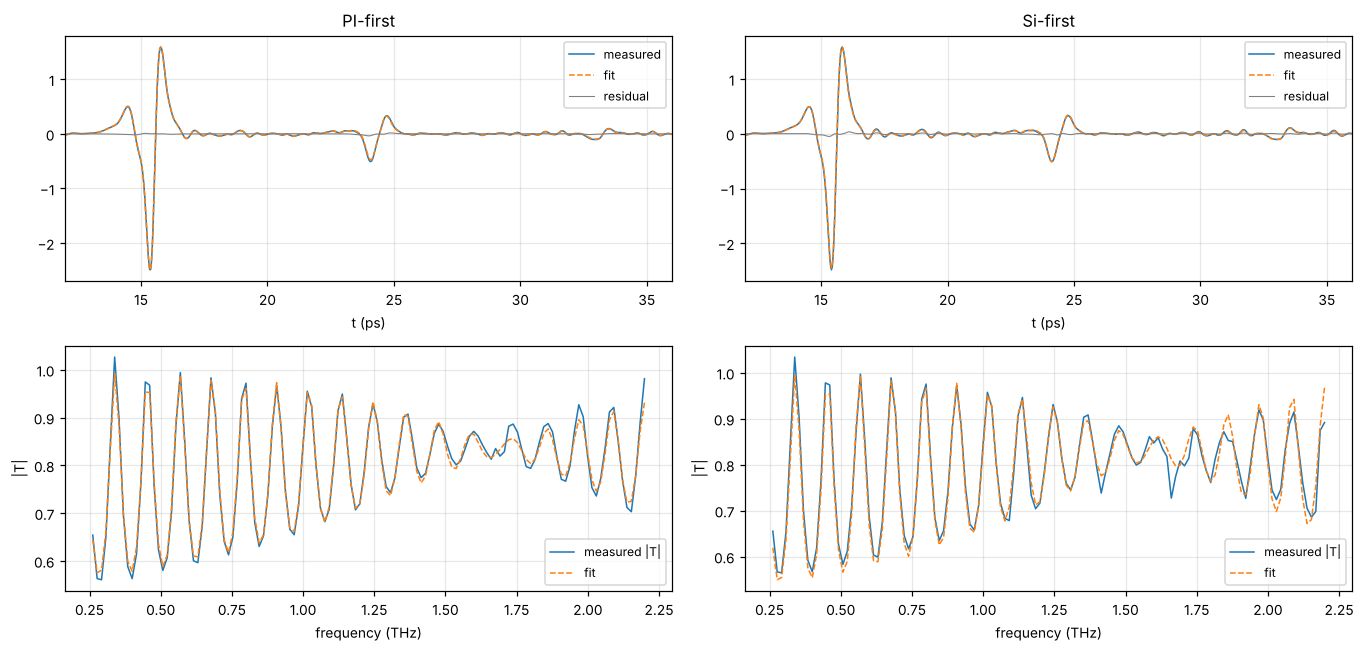

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(12.5, 6))
for j, (name, d) in enumerate(D.items()):
    yfit = simulate_np(d['x'], FIT[name]['p'], d['order'], d['dt'])
    ax[0, j].plot(d['t'], d['y'], lw=1.0, label='measured')
    ax[0, j].plot(d['t'], yfit, lw=1.0, ls='--', label='fit')
    ax[0, j].plot(d['t'], d['y']-yfit, lw=0.7, color='0.5', label='residual')
    ax[0, j].set_xlim(12, 36); ax[0, j].set_title(name)
    ax[0, j].set_xlabel('t (ps)'); ax[0, j].legend(fontsize=8)
    f, b = d['f'], d['band']
    Tm = modelT(f[b], FIT[name]['p'], d['order'])
    ax[1, j].plot(f[b]/1e12, np.abs(d['T'][b]), lw=1.0, label='measured |T|')
    ax[1, j].plot(f[b]/1e12, np.abs(Tm), lw=1.0, ls='--', label='fit')
    ax[1, j].set_xlabel('frequency (THz)'); ax[1, j].set_ylabel('|T|'); ax[1, j].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.2 Does the layer order change the answer?

In [11]:
# Re-fit each measurement with the stack built the other way round, changing nothing else.
print(f'{"measurement":12s} {"stack":22s} {"n_PI":>7s} {"d_PI/um":>9s} {"n_Si":>8s} {"d_Si/um":>9s} {"resid":>8s}')
for name, d in D.items():
    for order in (d['order'], d['order'][::-1]):
        saved = d['order']; d['order'] = order
        p, e = lsq_fit(name, starts=[FIT[name]['p']])
        d['order'] = saved
        tag = 'as measured' if order == d['order'] else 'reversed'
        print(f'{name:12s} {"air->"+"->".join(order)+"->air":22s} {p[0]:7.3f} {p[2]*1e6:9.2f} '
              f'{p[3]:8.4f} {p[5]*1e6:9.2f} {e:8.3f}   ({tag})')

measurement  stack                     n_PI   d_PI/um     n_Si   d_Si/um    resid
PI-first     air->PI->Si->air         1.730     25.54   3.2569    400.50    2.553   (as measured)
PI-first     air->Si->PI->air         1.730     25.54   3.2569    400.50    2.553   (reversed)
Si-first     air->Si->PI->air         1.756     26.83   3.4610    376.64    3.644   (as measured)


Si-first     air->PI->Si->air         1.756     26.83   3.4610    376.64    3.644   (reversed)


## 6. Summary

The polyimide index comes out at **n = 1.730 and 1.756** on the two measurements, with the film thickness
landing at **25.5 and 26.8 µm**. The product n·d, which is what the interference in the pulse actually
measures, agrees better than either factor alone.

The two measurements do not give identical silicon numbers — n_Si = 3.26 against 3.46. The pulse arrival
time relative to the reference differs by 81 fs between the two days (section 2.1), and that difference
feeds directly into how the fit divides the silicon's optical thickness into an index and a thickness.
For the polyimide the effect is much weaker, because its index is fixed mostly by the size of the
transmitted signal rather than by the arrival time.

Section 5.2 shows the layer order makes no difference to the fitted parameters.